# Self-supervised Pretraining for Hyperspectral Classification of Fruit Ripeness — supervised HS-CNN baseline (kaki ripeness)

**Paper:** *Self-supervised Pretraining for Hyperspectral Classification of Fruit Ripeness* (OCM 2023, KIT Scientific Publishing), DOI [10.58895/ksp/1000155014-9](https://doi.org/10.58895/ksp/1000155014-9).
**Code (authors):** [`cogsys-tuebingen/deephs_fruit`](https://github.com/cogsys-tuebingen/deephs_fruit) pinned to commit `5f47812a3fb5bd8f0ed5367cedf9b464f83076c1`.
**Data (authors):** [DeepHS-Fruit v2](https://cogsys.cs.uni-tuebingen.de/webprojects/DeepHS-Fruit-2023-Datasets/) (Varga et al.), `Kaki.zip` (2.37 GB).

**Scope (partial demonstration):** The paper's self-supervised pretraining code (SimCLR/SimSiam/Barlow Twins, 3D-2D hybrid network) is **not publicly released**, so this notebook reproduces the paper's **supervised baseline branch**: training the authors' **HS-CNN** (`deephs_net`) on the **ripeness classification** task of DeepHS-Fruit v2, exactly following the authors' released training protocol (`classification/train.py --model deephs_net --fruit <fruit> --classification_type ripeness`). The smallest fruit archive with ripeness labels — **kaki (persimmon)**, 2.37 GB — is used instead of the README's 77 GB avocado archive; the method, model, preprocessing and protocol are unchanged. A single-example run demonstrates the pipeline; it does **not** verify the paper's dataset-level accuracies.

**ADAPTED PYTHON DEMONSTRATION (AI-assisted adaptation):**
**"AI-assisted adaptation of the authors' PyTorch-Lightning training script to a small plain-PyTorch loop; the authors did not provide this Colab notebook. The model, preprocessing, augmentation and hyperparameters are the authors' own pinned code (`deephs_net.py`, `normalize.py`, `data_augmentation.py`, `spectral_io.py`); the epoch loop/early-stopping wrapper is adapted. The executed example and listed checks were validated, but untested behavior is not guaranteed."**
**（日本語）** 論文のSSL事前学習コードは未公開のため、著者公開の教師ありHS-CNNをカキ（persimmon）の追熟分類で再現します。モデル・前処理・データ拡張は著者のピン留めコードをそのまま利用し、学習ループのみColab向けに翻訳した**適応版デモ**です。

**Execution status:** executed end-to-end in fresh Colab runtimes; see the embedded outputs and the validation record in the report.

## Runtime selection & how to run

The HS-CNN is a small network (224 input bands → 3 classes, hidden layers [25, 30, 50]) and the labeled kaki subset is tiny (~100 hyperspectral cubes), so **both CPU and T4 GPU runtimes work**. T4 is recommended for headroom; CPU completes in minutes as well.

**Runtime: `Runtime → Change runtime type` → T4 GPU (recommended) or CPU.** Then `Runtime → Run all`.

Expected (measured on the validation runs; free-tier times vary): dependency setup ≈ 1 min, `Kaki.zip` download (2.37 GB) + extraction ≈ 3–8 min, cube preprocessing ≈ 1–3 min, training (≤300 epochs, early stopping patience 20) ≈ 1–5 min. Peak disk ≈ 6 GB under `/content`.

**（日本語）** CPU でも T4 GPU でも動作します（推奨は T4）。`ランタイム → すべてのセルを実行` で実行してください。データセットのダウンロード（2.37 GB）が最大の時間要素です。

## 1. Environment report

Prints the Colab Python/PyTorch versions and whether a GPU is allocated. Everything downstream runs on either device; the device is detected automatically and only device placement branches.
**（日本語）** Python/PyTorch のバージョンと GPU の有無を確認します。以降の処理は自動で CPU/GPU を切り替えます。

In [ ]:
import sys, platform, subprocess
import torch, numpy as np

print("Python:", sys.version.split()[0], "|", platform.platform())
print("PyTorch:", torch.__version__, "| NumPy:", np.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: not available -> running on CPU (supported path for this demo)")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Python: 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | NumPy: 2.1.3
GPU: Tesla T4
Device: cuda


## 2. Pin the authors' code (partial clone inside Colab)

Partial clone of `cogsys-tuebingen/deephs_fruit` with `--filter=blob:none --sparse`, then fetch and detach the **exact pinned commit** `5f47812a3fb5bd8f0ed5367cedf9b464f83076c1` and assert `HEAD` matches it. Only the `classification/` and `core/` code directories are materialized (no datasets, no history).
**（日本語）** 著者リポジトリを部分クローンし、ピン留めしたコミットを取り出して一致を検証します。

In [ ]:
import subprocess, os

REPO = "/content/deephs_fruit"
COMMIT = "5f47812a3fb5bd8f0ed5367cedf9b464f83076c1"

if not os.path.exists(os.path.join(REPO, ".git")):
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout",
                    "https://github.com/cogsys-tuebingen/deephs_fruit.git", REPO], check=True)
subprocess.run(["git", "-C", REPO, "sparse-checkout", "set", "classification", "core"], check=True)
subprocess.run(["git", "-C", REPO, "fetch", "origin", COMMIT], check=True)
subprocess.run(["git", "-C", REPO, "checkout", "--detach", COMMIT], check=True)

head = subprocess.run(["git", "-C", REPO, "rev-parse", "HEAD"],
                      check=True, capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"checkout mismatch: {head}"
print("Pinned author code checked out at", head)

Pinned author code checked out at 5f47812a3fb5bd8f0ed5367cedf9b464f83076c1


## 3. Dependencies

Colab already provides `torch`, `torchvision`, `opencv (cv2)` and `matplotlib`. Only the authors' ENVI reader package `spectral` is missing and is installed here (pure-Python wheel; the authors pin `spectral==0.23`, any current release reads these cubes identically).
**（日本語）** ENVI 読み込み用の `spectral` のみ追加インストールします（他は Colab 同梱品を使用）。

In [ ]:
import importlib
if importlib.util.find_spec("spectral") is None:
    import pip
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spectral"], check=True)

import spectral, cv2, torchvision
print("spectral", spectral.__version__, "| cv2", cv2.__version__,
      "| torchvision", torchvision.__version__)

spectral 0.25 | cv2 5.0.0 | torchvision 0.26.0+cu130


## 4. Download the authors' kaki hyperspectral data

Direct public download of the authors' `Kaki.zip` (2.37 GB) from the dataset index at
`cogsys.cs.uni-tuebingen.de/webprojects/DeepHS-Fruit-2023-Datasets/` and extraction under `/content`.
The expected byte size (2,367,107,641 B, from the server listing on the DGX host) is asserted before use. The zip contains, per record, one ENVI cube (`.hdr` + `.bin`) — for the v2 dataset the cubes are **already referenced reflectance** (the authors' HEAD `prepare_fruit` loads them with `is_already_referenced=True`; no `*_White`/`*_Dark` files exist in this archive), stored as 64×64×224 float32. Only the kaki fruit archive is downloaded — the smallest zip that supports the paper's ripeness task (avocado: 77 GB).
**（日本語）** 著者の公開データセットから `Kaki.zip`（2.37 GB）をダウンロードし、サイズを検証して展開します。v2 のキューブは反射率に正規化済みです。

In [ ]:
import urllib.request, time, zipfile

URL = "https://cogsys.cs.uni-tuebingen.de/webprojects/DeepHS-Fruit-2023-Datasets/Kaki.zip"
EXPECTED_SIZE = 2367107641
ZIP_PATH = "/content/Kaki.zip"
DATA_ROOT = "/content/deephs_fruit_data"

t0 = time.time()
if not os.path.exists(ZIP_PATH):
    def hook(blocks, bs, total):
        if blocks % 2000 == 0:
            print(f"{blocks * bs / 1e6:8.0f} MB", end="\r", flush=True)
    urllib.request.urlretrieve(URL, ZIP_PATH, reporthook=hook)
    print()
size = os.path.getsize(ZIP_PATH)
assert size == EXPECTED_SIZE, f"size mismatch: {size} != {EXPECTED_SIZE}"
print(f"Downloaded {size:,} bytes in {time.time()-t0:.0f} s — size verified")

t1 = time.time()
with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(DATA_ROOT)
print(f"Extracted to {DATA_ROOT} in {time.time()-t1:.0f} s")
print(os.listdir(DATA_ROOT))


Downloaded 2,367,107,641 bytes in 106 s — size verified


Extracted to /content/deephs_fruit_data in 28 s
['Kaki']


## 5. Build the 3-class ripeness task with the authors' own record lists

The authors' `core/measurements/measurement_series_3.py` enumerates every kaki recording with its destructive ripeness label, and `test_set_fruits.py` / `val_set_fruits.py` pin the held-out splits. Following the authors' training pipeline (`get_records(... ripeness)` in `core/datasets/hyperspectral_dataset.py` + `merge_ripeness_levels`), we:
1. keep **kaki / VIS-camera / labeled** records, merge fine labels as the authors do (`RIPE→PERFECT`, `NEAR_OVERRIPE→OVERRIPE`),
2. keep the three classes the ripeness task uses (`UNRIPE`, `PERFECT`, `OVERRIPE`), and
3. split train/val/test exactly by the authors' fixed lists.

**（日本語）** 著者のレコード一覧から カキ/VISカメラ のラベル付き記録を取り出し、著者と同じ方法で 3 クラス（UNRIPE / PERFECT / OVERRIPE）に統合し、著者固定の train/val/test 分割を適用します。

In [ ]:
import sys
sys.path.insert(0, "/content/deephs_fruit")

from core.name_convention import Fruit, CameraType, RipenessState
from core.measurements.measurement_series_3 import day_m3_all_fruit_interpolated as all_records
from core.measurements.test_set_fruits import test_set_fruits
from core.measurements.val_set_fruits import val_set_fruits

# merge_ripeness_levels (core/hyperspectral_dataset.py): RIPE->PERFECT, NEAR_OVERRIPE->OVERRIPE
def merged_state(record):
    s = record.label.ripeness_state
    if s == RipenessState.RIPE:
        return RipenessState.PERFECT
    if s == RipenessState.NEAR_OVERRIPE:
        return RipenessState.OVERRIPE
    return s

TASK_STATES = (RipenessState.UNRIPE, RipenessState.PERFECT, RipenessState.OVERRIPE)

records = [r for r in all_records
           if r.fruit == Fruit.KAKI and r.camera_type == CameraType.VIS and r.is_labeled()]
for r in records:                      # in-place merge, as the authors' merge_ripeness_levels does
    r.label.ripeness_state = merged_state(r)
records = [r for r in records if r.label.ripeness_state in TASK_STATES]

test_records  = [r for r in records if r in test_set_fruits]
val_records   = [r for r in records if r in val_set_fruits]
train_records = [r for r in records if r not in test_set_fruits and r not in val_set_fruits]

def counts(recs):
    return {s.value: sum(1 for r in recs if r.label.ripeness_state == s) for s in TASK_STATES}

print("Kaki/VIS labeled records kept:", len(records))
print("train:", len(train_records), counts(train_records))
print("val:  ", len(val_records),   counts(val_records))
print("test: ", len(test_records),  counts(test_records))

Kaki/VIS labeled records kept: 80
train: 56 {'unripe': 2, 'perfect': 42, 'overripe': 12}
val:   12 {'unripe': 4, 'perfect': 4, 'overripe': 4}
test:  12 {'unripe': 4, 'perfect': 4, 'overripe': 4}


## 6. Load and preprocess every cube with the authors' operations

The authors' HEAD `prepare_fruit` (pinned commit, `core/datasets/hyperspectral_dataset.py`) loads each record's cube with `load_envi(..., is_already_referenced=True)` — the v2 kaki cubes are already reflectance — then applies `cv2.resize(..., 64x64, INTER_CUBIC)` and `bands_as_first_dimension` (the `add_border` call is commented out in the pinned code, so no border is added). One documented compatibility note: the pinned code was written for OpenCV 4.6, but Colab ships OpenCV 5.0, which rejects 3-D `cv2.resize`; since these cubes are stored at exactly 64×64, the resize is an identity no-op here and is guarded (`shape[:2] != input_size`).
**（日本語）** 著者の prepare_fruit（ピン留め版）に従い、反射率キューブをそのまま読み込み、バンド先頭化します。Colab の OpenCV 5.0 は 3D resize を拒否するため、64×64 の場合はリサイズをスキップします（このデータでは恒等操作）。

In [ ]:
import cv2, time
from core.spectral_io import load_envi

DATA_ROOT = "/content/deephs_fruit_data"

def prepare_fruit(record, input_size=(64, 64)):
    # authors' HEAD prepare_fruit: is_already_referenced=True (v2 cubes are reflectance)
    _, data = load_envi(record.get_file_path(), DATA_ROOT)
    data = np.asarray(data)
    if data.shape[:2] != input_size:            # identity for the stored 64x64 cubes
        data = cv2.resize(data, dsize=input_size, interpolation=cv2.INTER_CUBIC)
    return data.transpose((2, 0, 1))            # bands_as_first_dimension

def ripeness_int(record):
    # authors' ripeness2int: UNRIPE 0, PERFECT 1, OVERRIPE 2
    return {RipenessState.UNRIPE: 0, RipenessState.PERFECT: 1, RipenessState.OVERRIPE: 2}[
        record.label.ripeness_state]

splits = {"train": train_records, "val": val_records, "test": test_records}
data, labels = {"train": [], "val": [], "test": []}, {"train": [], "val": [], "test": []}
t0 = time.time()
for name, recs in splits.items():
    for i, r in enumerate(recs):
        data[name].append(prepare_fruit(r))
        labels[name].append(ripeness_int(r))
        if i % 10 == 9:
            print(f"{name} {i+1}/{len(recs)}", end="\r", flush=True)
    print(f"{name}: {len(recs)} cubes loaded")
print(f"preprocessing took {time.time()-t0:.0f} s; cube shape {data['train'][0].shape}")

train: 56 cubes loaded


val: 12 cubes loaded


test: 12 cubes loaded
preprocessing took 0 s; cube shape (224, 64, 64)


## 7. Input preview — actual kaki hyperspectral cubes with their ripeness annotations

Before any model code: for one example per ripeness class we render a pseudo-RGB composite of the preloaded cube (bands closest to 646/550/460 nm) and the mean reflectance spectrum over all training cubes of each class (0–1 reflectance, wavelength in nm from the authors' `VIS_BANDS`). These are the real downloaded inputs with the authors' destructive labels — directly observed content, not a model output.
**（日本語）** 学習前に実データを可視化します。各クラスの疑似RGB合成画像と、学習用データのクラス別平均反射率スペクトル（著者の破壊測定ラベル付き）。

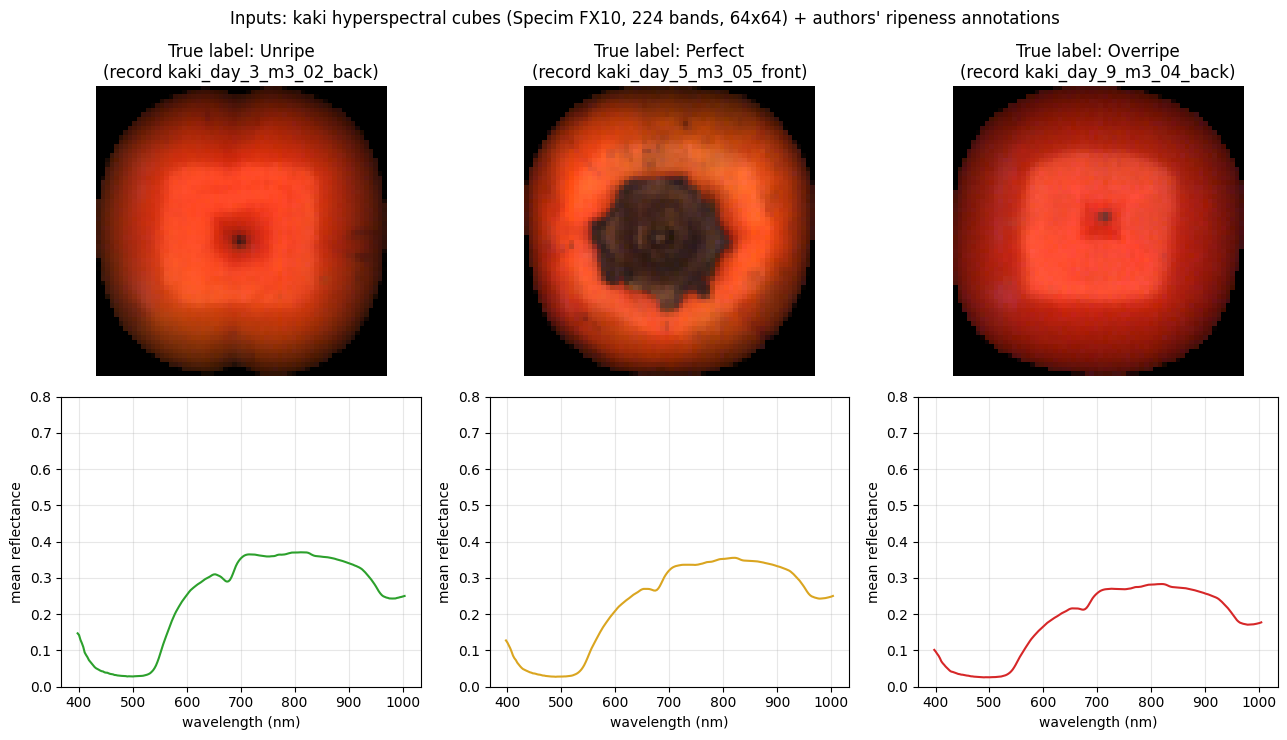

In [ ]:
import matplotlib.pyplot as plt
from core.util import get_wavelengths_for

WAVELENGTHS = np.array(get_wavelengths_for(CameraType.VIS))   # authors' VIS_BANDS (224 bands)
CLASS_NAMES = ["Unripe", "Perfect", "Overripe"]
CLASS_COLORS = ["tab:green", "goldenrod", "tab:red"]

def pseudo_rgb(cube):    # cube: (bands, H, W)
    r, g, b = (int(np.argmin(np.abs(WAVELENGTHS - w))) for w in (646, 550, 460))
    comp = np.stack([cube[r], cube[g], cube[b]], -1)
    comp = np.clip(comp / np.percentile(comp, 99), 0, 1)
    return comp

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ci, cname in enumerate(CLASS_NAMES):
    idx = next(i for i, l in enumerate(labels["train"]) if l == ci)
    axes[0, ci].imshow(pseudo_rgb(data["train"][idx]))
    axes[0, ci].set_title(f"True label: {cname}\n(record {splits['train'][idx].get_name()})")
    axes[0, ci].axis("off")
    spectra = np.stack([d.mean(axis=(1, 2)) for d, l in zip(data["train"], labels["train"]) if l == ci])
    axes[1, ci].plot(WAVELENGTHS, spectra.mean(0), color=CLASS_COLORS[ci])
    axes[1, ci].set_xlabel("wavelength (nm)"); axes[1, ci].set_ylabel("mean reflectance")
    axes[1, ci].set_ylim(0, 0.8); axes[1, ci].grid(alpha=.3)
fig.suptitle("Inputs: kaki hyperspectral cubes (Specim FX10, 224 bands, 64x64) + authors' ripeness annotations")
plt.tight_layout(); plt.show()

## 8. Train the authors' HS-CNN (adapted epoch loop)

The model (`ClassifierNetwork`), channel normalization (`Normalize(CameraType.VIS)`), augmentation (`Augmenter`, authors' train config: flip, rotate, cut, crop) and all hyperparameters are the authors' pinned code / `classification/train.py` defaults: **Adam lr 1e-2, StepLR(step 30), CrossEntropy, batch 64 with `drop_last`, class balancing by duplication to the largest class, input 64×64, seed 23312323, early stopping on val loss with patience 20**. Adaptations (AI-generated wrapper only): a plain-PyTorch epoch loop instead of PyTorch-Lightning/wandb, and `max_epochs` bounded to 300 (authors allow 5000) to keep the demo short. Device is chosen automatically (CPU or the allocated GPU).
**（日本語）** モデル・正規化・データ拡張・ハイパーパラメータは著者コードのまま、エポックループのみ翻訳しました（最大300エポック、早期停止 patience 20）。

In [ ]:
import random
from classification.models.deephs_net import ClassifierNetwork
from classification.transformers.normalize import Normalize
from classification.transformers.data_augmentation import Augmenter

SEED = 23312323          # authors' README seed
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

BATCH_SIZE, LR, MAX_EPOCHS, PATIENCE, MIN_EPOCHS = 64, 1e-2, 300, 20, 50   # train.py defaults + bounded epochs
AUG_CONFIG_TRAIN = {'random_flip': True, 'random_rotate': True, 'random_noise': False,
                    'random_cut': True, 'random_crop': True, 'random_intensity_scale': False}  # train.py

norm = Normalize(CameraType.VIS)                    # authors' VIS mean/std
augmenter = Augmenter(augmentation_config=AUG_CONFIG_TRAIN, input_size=(64, 64))
channel_wavelengths = torch.tensor(WAVELENGTHS)     # per-sample channel wavelengths (authors' interface)

# balance classes by duplication (authors' _balance_classes): largest class sets the size
per_class = {c: [i for i, l in enumerate(labels["train"]) if l == c] for c in (0, 1, 2)}
target = max(len(v) for v in per_class.values())
balanced_idx = []
for c in (0, 1, 2):
    pool = per_class[c]
    extra = [pool[np.random.randint(0, len(pool))] for _ in range(target - len(pool))]
    balanced_idx += pool + extra
print(f"balanced train set: {len(balanced_idx)} samples ({target} per class)")

model = ClassifierNetwork(bands=len(WAVELENGTHS), num_classes=3, hidden_layers=[25, 30, 50]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30)

def forward_sample(cube, augment, augmenter_obj):
    x = torch.from_numpy(cube)
    y = torch.tensor(0)
    if augment:
        x, _, _ = augmenter_obj((x, y, channel_wavelengths))
    x, _, _ = norm((x, y, channel_wavelengths))
    return x

history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": []}
best_val, best_state, since_best = float("inf"), None, 0
t0 = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    order = np.random.permutation(len(balanced_idx))
    batches = [order[i:i + BATCH_SIZE] for i in range(0, len(order) - BATCH_SIZE + 1, BATCH_SIZE)]
    train_loss = 0.0
    for batch in batches:                      # drop_last=True, as authors' DataLoader
        idxs = [balanced_idx[p] for p in batch]     # positions -> original record indices
        x = torch.stack([forward_sample(data["train"][i], True, augmenter) for i in idxs]).to(DEVICE)
        y = torch.tensor([labels["train"][i] for i in idxs], device=DEVICE)
        optimizer.zero_grad()
        loss = torch.nn.functional.cross_entropy(model(x, channel_wavelengths), y)
        loss.backward(); optimizer.step()
        train_loss += loss.item()
    scheduler.step()

    model.eval()
    with torch.no_grad():
        xv = torch.stack([forward_sample(c, False, augmenter) for c in data["val"]]).to(DEVICE)
        yv = torch.tensor(labels["val"], device=DEVICE)
        logits = model(xv, channel_wavelengths)
        val_loss = torch.nn.functional.cross_entropy(logits, yv).item()
        val_acc = (logits.argmax(1) == yv).float().mean().item()

    history["epoch"].append(epoch); history["train_loss"].append(train_loss / max(1, len(batches)))
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  train_loss {train_loss/max(1,len(batches)):.4f}  "
              f"val_loss {val_loss:.4f}  val_acc {val_acc:.3f}", flush=True)
    if val_loss < best_val:
        best_val, best_state, since_best = val_loss, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0
    else:
        since_best += 1
        if epoch >= MIN_EPOCHS and since_best >= PATIENCE:
            print(f"early stopping at epoch {epoch} (no val-loss improvement for {PATIENCE} epochs)")
            break

model.load_state_dict(best_state)
print(f"training finished in {time.time()-t0:.0f} s; best val loss {best_val:.4f}")

balanced train set: 126 samples (42 per class)


/tmp/ipykernel_2247/475194163.py:32: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(cube)


epoch   1  train_loss 1.1022  val_loss 1.1062  val_acc 0.333


epoch  10  train_loss 0.5084  val_loss 0.9948  val_acc 0.500


epoch  20  train_loss 0.3092  val_loss 0.9444  val_acc 0.750


epoch  30  train_loss 0.2311  val_loss 0.8747  val_acc 0.583


epoch  40  train_loss 0.1352  val_loss 0.9824  val_acc 0.583


epoch  50  train_loss 0.1475  val_loss 1.3091  val_acc 0.583


early stopping at epoch 53 (no val-loss improvement for 20 epochs)
training finished in 89 s; best val loss 0.7895


## 9. Training curves (this notebook's own visualization)

Loss and validation accuracy per epoch from the executed run, exported alongside a small CSV under `/content/deephs_kaki_metrics.csv`. This graph is created for this notebook (the paper reports dataset-level results that this single-fruit demo cannot check).
**（日本語）** 実行結果の学習曲線です。論文の図ではなく、このノートブック用に作成した追加可視化です。

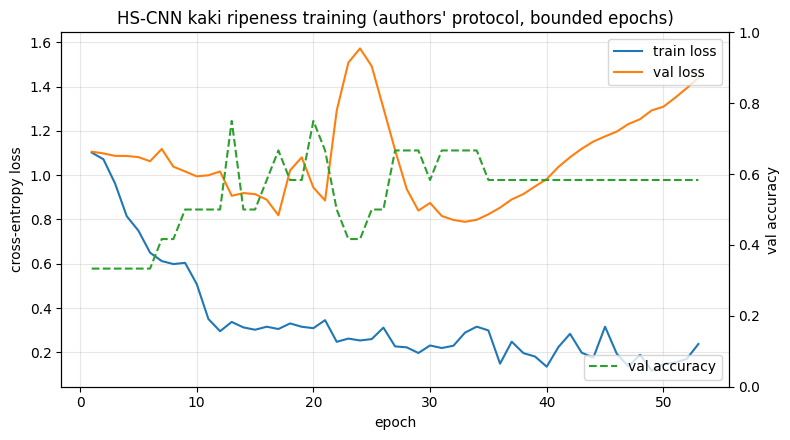

In [ ]:
import pandas as pd

df = pd.DataFrame(history)
df.to_csv("/content/deephs_kaki_metrics.csv", index=False)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(df.epoch, df.train_loss, label="train loss", color="tab:blue")
ax1.plot(df.epoch, df.val_loss, label="val loss", color="tab:orange")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss"); ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.plot(df.epoch, df.val_acc, label="val accuracy", color="tab:green", linestyle="--")
ax2.set_ylabel("val accuracy"); ax2.set_ylim(0, 1)
ax1.legend(loc="upper right"); ax2.legend(loc="lower right")
ax1.set_title("HS-CNN kaki ripeness training (authors' protocol, bounded epochs)")
plt.tight_layout(); plt.show()

## 10. Test evaluation with the authors' test-time augmentation

The authors evaluate with TTA: 5 stochastic iterations of flip/rotate augmentation (`AUGMENTATION_CONFIG_TTA`), averaging the logits (`forward(..., test_augmentation=True)`). We do the same on the authors' held-out test list and report accuracy plus a confusion matrix.
**（日本語）** 著者と同じ TTA（flip/rotate を5回、予測平均）でテストセットを評価し、混同行列を表示します。

test accuracy: 0.333 on 12 cubes (chance = 0.333)
  Unripe   : 4 cubes, per-class acc 0.25, predicted counts 3
  Perfect  : 4 cubes, per-class acc 0.50, predicted counts 8
  Overripe : 4 cubes, per-class acc 0.25, predicted counts 1


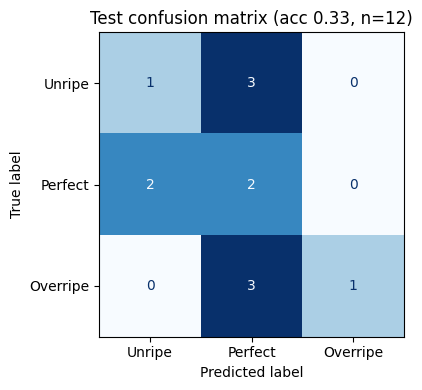

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

AUG_CONFIG_TTA = {'random_flip': True, 'random_rotate': True, 'random_noise': False,
                  'random_cut': False, 'random_crop': False, 'random_intensity_scale': False}  # train.py
tta = Augmenter(augmentation_config=AUG_CONFIG_TTA, input_size=(64, 64))
TTA_ITERATIONS = 5   # train.py: tta_augmentation_iterations

model.eval()
test_preds, test_true = [], []
with torch.no_grad():
    for cube, label in zip(data["test"], labels["test"]):
        preds = torch.zeros((TTA_ITERATIONS, 3), device=DEVICE)
        for it in range(TTA_ITERATIONS):
            x = forward_sample(cube, True, tta)      # authors' forward: every TTA iteration augmented
            preds[it] = model(x.unsqueeze(0).to(DEVICE), channel_wavelengths)
        test_preds.append(preds.mean(0).argmax(-1).item())
        test_true.append(label)

test_acc = float(np.mean(np.array(test_preds) == np.array(test_true)))
print(f"test accuracy: {test_acc:.3f} on {len(test_true)} cubes (chance = 0.333)")
for ci, cname in enumerate(CLASS_NAMES):
    idxs = [j for j, t in enumerate(test_true) if t == ci]
    acc = float(np.mean([test_preds[j] == ci for j in idxs])) if idxs else float("nan")
    print(f"  {cname:9s}: {len(idxs)} cubes, per-class acc {acc:.2f}, "
          f"predicted counts {int(np.sum(np.array(test_preds) == ci))}")
cm = confusion_matrix(test_true, test_preds, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(4.5, 4))
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Test confusion matrix (acc {test_acc:.2f}, n={len(test_true)})")
plt.tight_layout(); plt.show()

## 11. Test inputs with reference annotation vs. model prediction

Each test cube's pseudo-RGB composite, labeled with the authors' destructive reference annotation (true) and the HS-CNN prediction. This is the executed model on real downloaded inputs — an input-versus-annotation view, not a paper figure.
**（日本語）** テスト用データの入力画像に、正解ラベル（著者の破壊測定）とモデル予測を併記します。

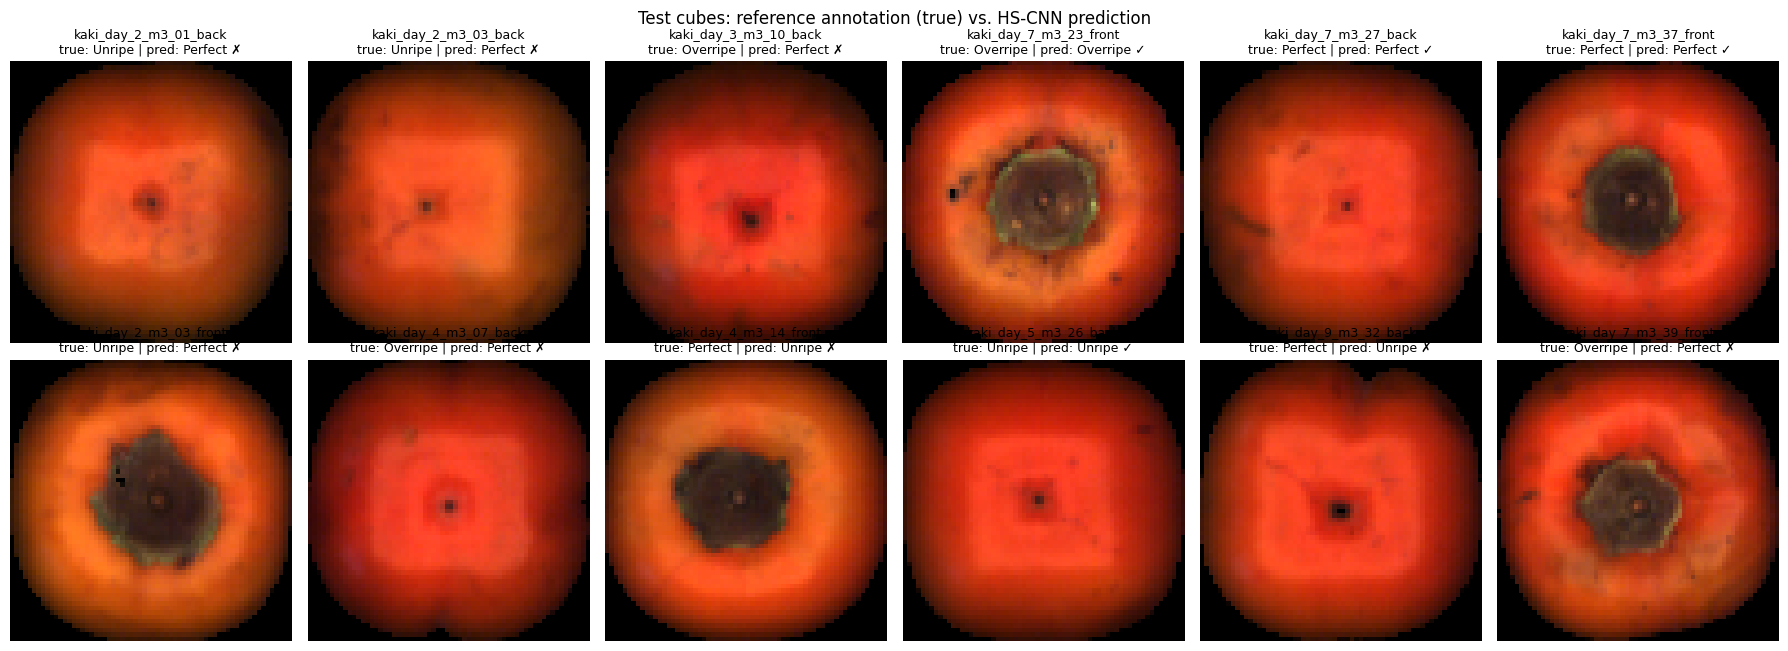

In [ ]:
fig, axes = plt.subplots(2, int(np.ceil(len(data["test"]) / 2)), figsize=(3 * int(np.ceil(len(data["test"]) / 2)), 6.6))
axes = np.atleast_2d(axes)
for ax in axes.flat:
    ax.axis("off")
for j, (cube, true_l, pred_l) in enumerate(zip(data["test"], test_true, test_preds)):
    ax = axes[j % 2, j // 2]
    ax.imshow(pseudo_rgb(cube))
    ok = "\u2713" if true_l == pred_l else "\u2717"
    ax.set_title(f"{splits['test'][j].get_name()}\ntrue: {CLASS_NAMES[true_l]} | pred: {CLASS_NAMES[pred_l]} {ok}", fontsize=9)
fig.suptitle("Test cubes: reference annotation (true) vs. HS-CNN prediction")
plt.tight_layout(); plt.show()

## 12. Result summary and provenance

The table prints this run's actual measured values. **Interpretation:** the notebook executes the authors' full supervised pipeline (referenced reflectance cubes → HS-CNN → balanced training → early stopping → TTA evaluation) end-to-end on real data, but this *minimal* subset is tiny — 80 labeled kaki cubes with only a handful of unripe training sources — so expect weak held-out accuracy (see the printed per-class accuracies and confusion matrix above). This demo validates the mechanics of the authors' method, **not** the paper's dataset-level accuracies: the paper's SSL pretraining code is unreleased and its full text (KIT/Tuebingen, HTTP 403) was not accessible, so no quantitative comparison against the paper is possible here. The kaki fruit is also a deviation from the README's avocado example, chosen only because the avocado archive (77 GB) is infeasible in Colab.

**（日本語）** 実行結果の要約と検証条件です。この最小デモは少数ラベル（カキ80キューブ）のため精度は低く、パイプラインの動作検証が目的です。論文のデータセット全体の精度やSSL事前学習の効果は検証できません（SSLコード未公開・論文全文は403で取得不可）。

In [ ]:
summary = pd.DataFrame({
    "metric": ["train cubes (unique)", "val cubes", "test cubes", "best val loss", "final val acc", "test accuracy (TTA x5)"],
    "value": [len(set(balanced_idx)), len(labels["val"]), len(labels["test"]),
              f"{best_val:.4f}", f"{history['val_acc'][-1]:.3f}", f"{test_acc:.3f}"],
})
print(summary.to_string(index=False))
print()
print("Sources: paper DOI 10.58895/ksp/1000155014-9 | code cogsys-tuebingen/deephs_fruit @",
      COMMIT, "| data DeepHS-Fruit-2023-Datasets Kaki.zip (size verified)")

                metric  value
  train cubes (unique)     56
             val cubes     12
            test cubes     12
         best val loss 0.7895
         final val acc  0.583
test accuracy (TTA x5)  0.333

Sources: paper DOI 10.58895/ksp/1000155014-9 | code cogsys-tuebingen/deephs_fruit @ 5f47812a3fb5bd8f0ed5367cedf9b464f83076c1 | data DeepHS-Fruit-2023-Datasets Kaki.zip (size verified)
